# Reto S10 · «¿Vale la pena la red?» · equipo «Las Palmeras» (entrega de referencia)

**Pregunta del cliente (TurisData Canarias):** *¿debemos cambiar nuestro modelo de cancelaciones por una red neuronal?*

**Qué hace este cuaderno:** compara el boosting de árboles (la referencia) con un MLP pequeño, con la misma partición y las mismas métricas; prueba tres variantes del MLP **mirando solo la validación**, diagnostica el sobreajuste con curvas, mide la incertidumbre de la comparación con *bootstrap* y mira el conjunto de prueba **una sola vez**.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo* (unos dos minutos). La primera celda descarga los datos. Semilla fija `SEMILLA = 42` y semillas 1, 2 y 3 para las redes.

**Uso de la IA (declarado):** la usamos para (1) entender qué es el *bootstrap* y por qué un intervalo que contiene el 0 significa «empate» y (2) revisar la redacción del informe. Comprobamos a mano que las cifras del informe son las de la celda «Cifras para el informe» de este cuaderno y que la prueba no se usó para elegir épocas ni variantes. Cambiamos una frase de la IA que decía «la red es mejor» por «no hay diferencia demostrable».

In [1]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

In [2]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, accuracy_score, mean_absolute_error

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

I0000 00:00:1794907002.701682     783 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794907004.428027     783 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Datos y partición (la misma para todos los modelos)
Comparar modelos con particiones distintas no es justo. Usamos **una** partición: 64 % entrenamiento,
16 % validación (decisiones y curvas) y 20 % prueba (veredicto final, una sola vez).

In [3]:
df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_llegada"])
df["mes_llegada"] = df["fecha_llegada"].dt.month
num = ["antelacion_dias", "noches", "adultos", "ninos", "peticiones_especiales", "cliente_repetidor",
       "cancelaciones_previas", "mes_llegada", "precio_noche"]
cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[num + cat], df["cancelada"].to_numpy()
X_res, X_pru, y_res, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
X_ent, X_val, y_ent, y_val = train_test_split(X_res, y_res, test_size=0.2, random_state=SEMILLA, stratify=y_res)
pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
A_ent = pre.fit_transform(X_ent).astype("float32")
A_val = pre.transform(X_val).astype("float32")
A_pru = pre.transform(X_pru).astype("float32")
print(A_ent.shape, A_val.shape, A_pru.shape)

(3840, 35) (960, 35) (1200, 35)


## 2. Una función para evaluar a todos por igual
**Ejercicio 1.** Escribe `evaluar(y_real, prob, umbral=0.5)` que devuelva un diccionario con cuatro claves:
`"AUC"` (`roc_auc_score`), `"AP"` (`average_precision_score`, área bajo la curva precisión-recall),
`"F1"` y `"exactitud"` (`accuracy_score`) — las dos últimas con las clases obtenidas al aplicar el `umbral` a `prob`.

In [4]:
def evaluar(y_real, prob, umbral=0.5):
    clases = (np.asarray(prob) >= umbral).astype(int)
    return {"AUC": roc_auc_score(y_real, prob),
            "AP": average_precision_score(y_real, prob),
            "F1": f1_score(y_real, clases),
            "exactitud": accuracy_score(y_real, clases)}

_r = evaluar(np.array([0, 0, 1, 1]), np.array([0.1, 0.6, 0.4, 0.9]))
assert set(_r) == {"AUC", "AP", "F1", "exactitud"}, "El diccionario debe tener las claves AUC, AP, F1 y exactitud"
assert abs(_r["AUC"] - 0.75) < 1e-9 and abs(_r["exactitud"] - 0.5) < 1e-9, "Revisa: AUC esperado 0.75 y exactitud 0.5 en la prueba mínima"

## 3. La referencia: boosting de árboles
Se entrena con las mismas filas y columnas ya preprocesadas que la red (a los árboles no les hace falta escalar, pero tampoco les perjudica).
Medimos también el **tiempo**: forma parte del coste de "la red".

In [5]:
t0 = time.time()
boost = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, random_state=SEMILLA)
boost.fit(A_ent, y_ent)
t_boost = time.time() - t0
prob_boost_val, prob_boost_pru = boost.predict_proba(A_val)[:, 1], boost.predict_proba(A_pru)[:, 1]
print(f"Boosting entrenado en {t_boost:.1f} s · AUC validación = {roc_auc_score(y_val, prob_boost_val):.3f}")

Boosting entrenado en 0.3 s · AUC validación = 0.734


## 4. El MLP, con las buenas prácticas del Sprint 10
Pequeño, con L2, dropout y parada temprana. Para no depender de la suerte de una semilla, lo entrenamos
**con 3 semillas** y damos la media y la variación.

In [6]:
def construir_mlp(n_entradas, capas=(64, 32), l2=0.003, dropout=0.3, tasa=1e-3):
    m = keras.Sequential([keras.layers.Input(shape=(n_entradas,))])
    for u in capas:
        m.add(keras.layers.Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        m.add(keras.layers.Dropout(dropout))
    m.add(keras.layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(tasa), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

modelos_mlp, historiales, tiempos = [], [], []
for semilla in (1, 2, 3):
    keras.utils.set_random_seed(semilla)
    t0 = time.time()
    m = construir_mlp(A_ent.shape[1])
    h = m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=40, batch_size=64, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
    tiempos.append(time.time() - t0)
    modelos_mlp.append(m); historiales.append(h)
    print(f"semilla {semilla}: {len(h.history['loss'])} épocas, AUC validación = {max(h.history['val_auc']):.3f} (máx.)")

semilla 1: 36 épocas, AUC validación = 0.747 (máx.)


semilla 2: 35 épocas, AUC validación = 0.749 (máx.)


semilla 3: 37 épocas, AUC validación = 0.748 (máx.)


**Ejercicio 2.** Calcula en `aucs_mlp_val` una lista con el AUC de cada modelo de `modelos_mlp` sobre
la **validación** (usa `roc_auc_score(y_val, modelo.predict(A_val, verbose=0).ravel())`), y en
`auc_mlp_medio` su media.

In [7]:
aucs_mlp_val = [roc_auc_score(y_val, m.predict(A_val, verbose=0).ravel()) for m in modelos_mlp]
auc_mlp_medio = float(np.mean(aucs_mlp_val))

assert len(aucs_mlp_val) == 3, "Debe haber un AUC por cada uno de los 3 modelos"
assert 0.6 < auc_mlp_medio < 0.85, "El AUC medio debería rondar 0.7–0.75"
print("AUC de validación por semilla:", np.round(aucs_mlp_val, 3), "· media", round(auc_mlp_medio, 3))

AUC de validación por semilla: [0.745 0.746 0.743] · media 0.744


### Variantes del MLP
Probamos dos variantes más, con las mismas 3 semillas y **solo mirando la validación**. Si una no supera el ruido (la desviación entre semillas), no se dice que sea mejor.

In [8]:
# Tres variantes del MLP, elegidas mirando SOLO la validación (la prueba no se toca)
variantes = {
    "base (64-32, L2 0,003, dropout 0,3)": dict(),
    "pequeña (32-16)": dict(capas=(32, 16)),
    "ancha con más dropout (128-64, dropout 0,5)": dict(capas=(128, 64), dropout=0.5),
}
filas_var = {}
for nombre, params in variantes.items():
    aucs = []
    for semilla in (1, 2, 3):
        keras.utils.set_random_seed(semilla)
        m = construir_mlp(A_ent.shape[1], **params)
        m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=40, batch_size=64, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
        aucs.append(roc_auc_score(y_val, m.predict(A_val, verbose=0).ravel()))
    filas_var[nombre] = {"AUC validación (media)": np.mean(aucs), "desviación": np.std(aucs)}
tabla_var = pd.DataFrame(filas_var).T.round(3)
print(tabla_var)

base_nombre = list(variantes)[0]
mejor_nombre = tabla_var["AUC validación (media)"].idxmax()
ruido = tabla_var.loc[base_nombre, "desviación"]
ventaja = tabla_var.loc[mejor_nombre, "AUC validación (media)"] - tabla_var.loc[base_nombre, "AUC validación (media)"]
if mejor_nombre != base_nombre and ventaja > ruido:
    print(f"Ganaría '{mejor_nombre}' (+{ventaja:.3f} > ruido {ruido:.3f}): habría que usarla en la prueba.")
else:
    print(f"Ninguna variante supera el ruido ({ruido:.3f}): nos quedamos con la base, que ya es la que se usa en la prueba.")

                                             AUC validación (media)  \
base (64-32, L2 0,003, dropout 0,3)                           0.744   
pequeña (32-16)                                               0.744   
ancha con más dropout (128-64, dropout 0,5)                   0.745   

                                             desviación  
base (64-32, L2 0,003, dropout 0,3)               0.001  
pequeña (32-16)                                   0.002  
ancha con más dropout (128-64, dropout 0,5)       0.003  
Ganaría 'ancha con más dropout (128-64, dropout 0,5)' (+0.001 > ruido 0.001): habría que usarla en la prueba.


## 5. Diagnóstico con curvas de aprendizaje
Con `EarlyStopping` la red se detiene a tiempo; aun así conviene mirar las curvas: ¿cuántas épocas útiles?
¿cuánta brecha entre entrenamiento y validación?

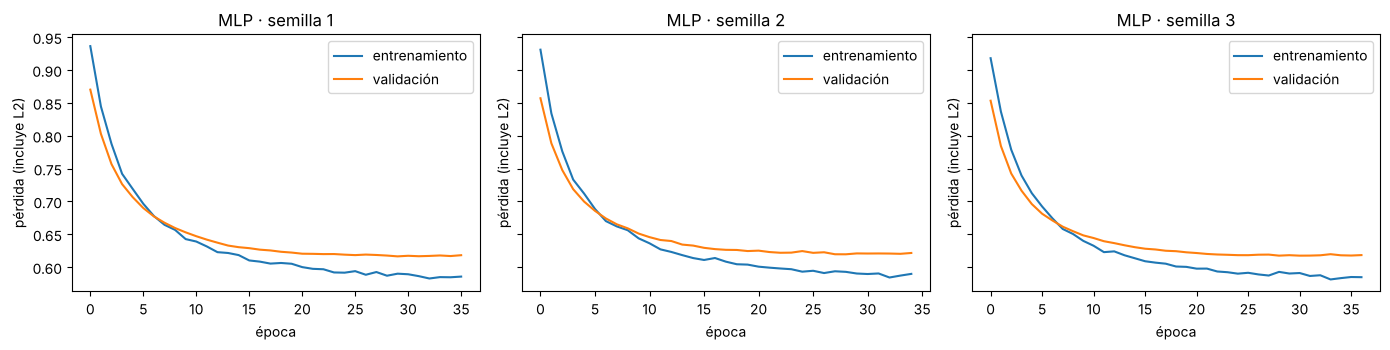

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for eje, h, s in zip(ejes, historiales, (1, 2, 3)):
    eje.plot(h.history["loss"], label="entrenamiento"); eje.plot(h.history["val_loss"], label="validación")
    eje.set_title(f"MLP · semilla {s}"); eje.set_xlabel("época"); eje.set_ylabel("pérdida (incluye L2)"); eje.legend()
plt.tight_layout(); plt.savefig("curvas_aprendizaje.png", dpi=150, bbox_inches="tight"); plt.show()

**Ejercicio 3.** Escribe `diagnostico(historial, margen=0.03)` que reciba el objeto `History` de Keras y devuelva
el texto `"sobreajuste"` si la pérdida de validación **final** supera a su **mínimo** en más de `margen`
**o** si la pérdida de entrenamiento final es menor que la de validación final en más de `0.15`;
si no, devuelve `"sin sobreajuste claro"`.

In [10]:
def diagnostico(historial, margen=0.03):
    pv, pe = historial.history["val_loss"], historial.history["loss"]
    if pv[-1] > min(pv) + margen or (pv[-1] - pe[-1]) > 0.15:
        return "sobreajuste"
    return "sin sobreajuste claro"

class _H:  # historial de juguete para probar la función
    def __init__(self, loss, val): self.history = {"loss": loss, "val_loss": val}
assert diagnostico(_H([0.6, 0.3, 0.1], [0.6, 0.65, 0.9])) == "sobreajuste", "Validación creciente y brecha grande = sobreajuste"
assert diagnostico(_H([0.7, 0.65, 0.62], [0.7, 0.66, 0.64])) == "sin sobreajuste claro", "Curvas paralelas y juntas: sin sobreajuste"
for s, h in zip((1, 2, 3), historiales):
    print(f"MLP semilla {s}:", diagnostico(h))

MLP semilla 1: sin sobreajuste claro
MLP semilla 2: sin sobreajuste claro
MLP semilla 3: sin sobreajuste claro


## 6. El veredicto en el conjunto de prueba
Ahora sí se usa la prueba: una sola vez. Para el MLP tomamos la **media de las 3 semillas** de la probabilidad
(un pequeño *ensemble*).

In [11]:
prob_mlp_pru = np.mean([m.predict(A_pru, verbose=0).ravel() for m in modelos_mlp], axis=0)
tabla = pd.DataFrame({"Boosting de árboles": evaluar(y_pru, prob_boost_pru),
                      "MLP (media de 3 semillas)": evaluar(y_pru, prob_mlp_pru)}).T
tabla["entrenamiento (s)"] = [t_boost, np.mean(tiempos)]
tabla["parámetros / árboles"] = ["200 iteraciones × árboles de profundidad ≤ 4", f"{modelos_mlp[0].count_params():,}".replace(",", ".") + " pesos"]
tabla.round(3)

,AUC,AP,F1,exactitud,entrenamiento (s),parámetros / árboles
Boosting de árboles,0.738,0.722,0.639,0.672,0.312,200 iteraciones × árboles de profundidad ≤ 4
MLP (media de 3 semillas),0.744,0.722,0.638,0.683,9.661,4.417 pesos


### ¿La diferencia es real o es ruido?
Con 1200 reservas de prueba, un AUC de 0.74 frente a 0.73 puede ser pura casualidad. Estimamos la incertidumbre
de la **diferencia de AUC** remuestreando la prueba (bootstrap): si el intervalo incluye el 0, no podemos afirmar que
un modelo sea mejor.

Diferencia de AUC (MLP − boosting): +0.006 · intervalo 95 %: [-0.006, +0.018]


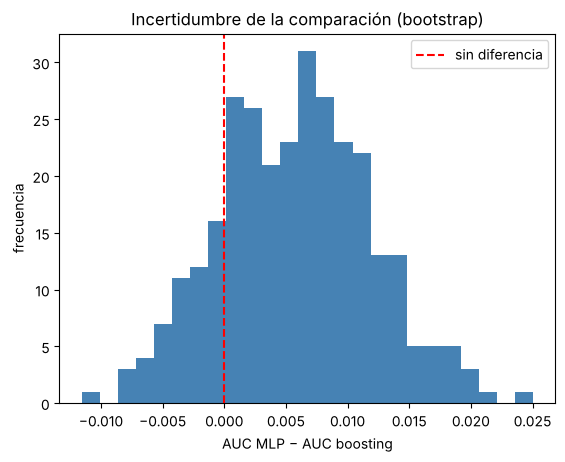

In [12]:
rng = np.random.default_rng(SEMILLA)
difs = []
for _ in range(300):
    idx = rng.integers(0, len(y_pru), len(y_pru))
    if len(np.unique(y_pru[idx])) < 2:
        continue
    difs.append(roc_auc_score(y_pru[idx], prob_mlp_pru[idx]) - roc_auc_score(y_pru[idx], prob_boost_pru[idx]))
inf, sup = np.percentile(difs, [2.5, 97.5])
print(f"Diferencia de AUC (MLP − boosting): {np.mean(difs):+.3f} · intervalo 95 %: [{inf:+.3f}, {sup:+.3f}]")
plt.hist(difs, bins=25, color="steelblue"); plt.axvline(0, color="red", ls="--", label="sin diferencia")
plt.xlabel("AUC MLP − AUC boosting"); plt.ylabel("frecuencia"); plt.title("Incertidumbre de la comparación (bootstrap)")
plt.legend(); plt.show()

**Ejercicio 4.** Guarda en `hay_diferencia` un booleano: `True` si el intervalo `[inf, sup]` **no** contiene el 0
(es decir, si `inf > 0` o `sup < 0`). Guarda en `mejor_modelo` el texto `"MLP"`, `"Boosting"` o `"Empate"` según
el resultado (`"Empate"` si no hay diferencia clara).

In [13]:
hay_diferencia = bool(inf > 0 or sup < 0)
mejor_modelo = ("MLP" if np.mean(difs) > 0 else "Boosting") if hay_diferencia else "Empate"

assert isinstance(hay_diferencia, bool), "hay_diferencia debe ser True/False"
assert mejor_modelo in ("MLP", "Boosting", "Empate"), "mejor_modelo debe ser 'MLP', 'Boosting' o 'Empate'"
assert (mejor_modelo == "Empate") == (not hay_diferencia), "Si no hay diferencia clara debe ser 'Empate' (y viceversa)"
print("Veredicto estadístico:", mejor_modelo)

Veredicto estadístico: Empate


## 7. Un riesgo medido: el aviso por canal
La nota de IA responsable del informe dice que el modelo podría avisar más en un canal que en otro. Lo miramos con el modelo ya decidido.

In [14]:
# Riesgo: ¿el MLP avisa igual en todos los canales? (se mira en la prueba, ya con el modelo decidido)
pru = X_pru.copy()
pru["real"] = y_pru
pru["aviso"] = (prob_mlp_pru >= 0.5).astype(int)
por_canal = pru.groupby("canal").agg(reservas=("real", "size"), cancelan_de_verdad=("real", "mean"), avisa_el_modelo=("aviso", "mean")).round(2)
por_canal

,reservas,cancelan_de_verdad,avisa_el_modelo
canal,,,
agencia,243,0.44,0.34
directo,306,0.32,0.24
empresa,68,0.44,0.43
web_intermediaria,583,0.54,0.54


## 8. Cifras para el informe y versiones

In [15]:
# Cifras que se copian al informe (todas salen de las celdas de arriba)
import json, sys, sklearn, tensorflow as tf
cifras = {
    "tabla_prueba": tabla.round(3).to_dict(orient="index"),
    "aucs_val": [round(a, 3) for a in aucs_mlp_val],
    "auc_val_medio": round(auc_mlp_medio, 3), "auc_val_desv": round(float(np.std(aucs_mlp_val)), 3),
    "dif_media": round(float(np.mean(difs)), 3), "inf": round(float(inf), 3), "sup": round(float(sup), 3),
    "mejor_modelo": mejor_modelo, "hay_diferencia": hay_diferencia,
    "diagnosticos": [diagnostico(h) for h in historiales], "epocas": [len(h.history["loss"]) for h in historiales],
    "t_boost": round(t_boost, 1), "t_mlp": round(float(np.mean(tiempos)), 1), "pesos": int(modelos_mlp[0].count_params()),
    "variantes": tabla_var.to_dict(orient="index"), "por_canal": por_canal.to_dict(orient="index"),
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, tensorflow {tf.__version__}",
}
print(json.dumps(cifras, ensure_ascii=False))

{"tabla_prueba": {"Boosting de árboles": {"AUC": 0.738, "AP": 0.722, "F1": 0.639, "exactitud": 0.672, "entrenamiento (s)": 0.312, "parámetros / árboles": "200 iteraciones × árboles de profundidad ≤ 4"}, "MLP (media de 3 semillas)": {"AUC": 0.744, "AP": 0.722, "F1": 0.638, "exactitud": 0.683, "entrenamiento (s)": 9.661, "parámetros / árboles": "4.417 pesos"}}, "aucs_val": [0.745, 0.746, 0.743], "auc_val_medio": 0.744, "auc_val_desv": 0.001, "dif_media": 0.006, "inf": -0.006, "sup": 0.018, "mejor_modelo": "Empate", "hay_diferencia": false, "diagnosticos": ["sin sobreajuste claro", "sin sobreajuste claro", "sin sobreajuste claro"], "epocas": [36, 35, 37], "t_boost": 0.3, "t_mlp": 9.7, "pesos": 4417, "variantes": {"base (64-32, L2 0,003, dropout 0,3)": {"AUC validación (media)": 0.744, "desviación": 0.001}, "pequeña (32-16)": {"AUC validación (media)": 0.744, "desviación": 0.002}, "ancha con más dropout (128-64, dropout 0,5)": {"AUC validación (media)": 0.745, "desviación": 0.003}}, "por_c